In [2]:
from src.utils.data_utils import load_final_df
from src.analysis.virality_analysis.get_viral_posts import get_viral_posts
import numpy as np
import pandas as pd
pd.set_option('display.max_columns', None)

df = load_final_df(calculate_rss=False, drop_nan_upvotes=False)
clean_df = df.iloc[:, list(range(92)) + [-3, -4]]
clean_df = clean_df.drop(columns=["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "POST_ID"])
clean_df["upvote_ratio"] = df["upvote_ratio"]
clean_df["subreddit_subscribers"] = df["subreddit_subscribers"]
clean_df["ups"] = df["ups"]
clean_df["downs"] = df["downs"]

nan_df = clean_df[clean_df["ups"].isna()]
non_nan_df = clean_df[~clean_df["ups"].isna()]

mask = non_nan_df['upvote_ratio'] > 0
total_votes = pd.Series(0.0, index=non_nan_df.index) # assumption: if ups = 0 or upvote_ratio = 0 we assume downs = 0
downs = pd.Series(0.0, index=non_nan_df.index)

total_votes.loc[mask] = non_nan_df.loc[mask, 'ups'] / non_nan_df.loc[mask, 'upvote_ratio']
downs.loc[mask] = total_votes.loc[mask] - non_nan_df.loc[mask, 'ups']

subreddit_subscribers = np.maximum(non_nan_df["subreddit_subscribers"], 0)

non_nan_df = non_nan_df.assign(
    total_votes=total_votes,
    downs=downs,
    subreddit_subscribers=subreddit_subscribers,
    virality_rss=((2*non_nan_df["ups"] + non_nan_df["downs"]) / np.sqrt(subreddit_subscribers + 1))
)

non_nan_df = get_viral_posts(non_nan_df, virality_percentile=0.98, window_size='60D')

In [ ]:
nan_df['sentiment_category'] = nan_df['Sentiment_compound_vader'].apply(
        lambda x: 'Negative' if x < -0.05 else ('Neutral' if x <= 0.05 else 'Positive')
    )

counts = nan_df.groupby(['source_supercluster', 'sentiment_category']).size().reset_index(name='count')
counts.to_csv('sentiment_counts_by_supercluster_unscraped.csv', index=False)

counts_rel = (
    clean_df
    .assign(ups_is_na=clean_df['ups'].isna())
    .groupby(['source_supercluster', 'ups_is_na'])
    .size()
    .unstack(fill_value=0)
)
counts_rel = counts_rel.div(counts_rel.sum(axis=0), axis=1)
counts_rel = (
    counts_rel
    .rename(columns={False: 'ups_present', True: 'ups_missing'})
    .reset_index()
)
counts_rel.to_csv('unscraped_counts_by_supercluster.csv', index=False)

C:\Users\clued\AppData\Local\Temp\ipykernel_18196\347411923.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nan_df['sentiment_category'] = nan_df['Sentiment_compound_vader'].apply(


: 

In [8]:
non_nan_df = pd.get_dummies(non_nan_df, columns=["source_supercluster", "target_supercluster", "source_type"], drop_first=True)
nan_df = pd.get_dummies(nan_df, columns=["source_supercluster", "target_supercluster", "source_type"], drop_first=True)
nan_df = nan_df.reindex(columns=non_nan_df.columns, fill_value=0)
nan_df = nan_df.drop(columns=["is_viral", "z_score", "moving_std_virality", "moving_avg_virality","virality_rss",
                              "upvote_ratio", "subreddit_subscribers", "ups", "downs", "total_votes", "TIMESTAMP"])
non_nan_df = non_nan_df.drop(columns=["TIMESTAMP", "z_score", "moving_std_virality", "moving_avg_virality","virality_rss",
                              "upvote_ratio", "subreddit_subscribers", "ups", "downs", "total_votes"])

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X = non_nan_df.drop(columns=["is_viral"])
y = non_nan_df["is_viral"] 

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42
)

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=3,
    class_weight={0:1, 1:70}
)

rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print("Accuracy:", acc)


Accuracy: 0.9563482201593451


In [10]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

cm = confusion_matrix(y_test, y_pred, labels=[True, False])
cm_df = pd.DataFrame(cm, index=["Actual True", "Actual False"], columns=["Pred True", "Pred False"])
print(f"Precision: {precision_score(y_test, y_pred)}")
print(f"Recall: {recall_score(y_test, y_pred)}")
print(f"F1 Score: {f1_score(y_test, y_pred)}")
cm_df

Precision: 0.12424663885025498
Recall: 0.19633699633699633
F1 Score: 0.1521862578080636


,Pred True,Pred False
Actual True,268,1097
Actual False,1889,65151


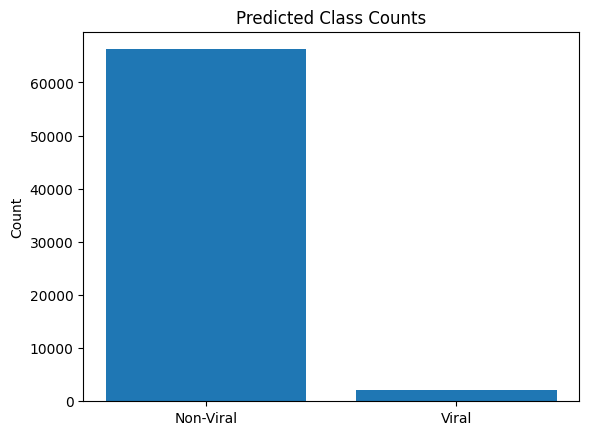

Percentage of predictions that are 1: 3.1532782691323735


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

nan_posts_pred = rf.predict(nan_df)
nan_df = nan_df.assign(is_viral_pred=nan_posts_pred)

mask = nan_df.filter(like="source_supercluster_").sum(axis=1) > 0

nan_df["source_supercluster"] = (
    nan_df.filter(like="source_supercluster_")
          .idxmax(axis=1)
          .where(mask)
          .str.replace("source_supercluster_", "")
)

nan_df.loc[~mask, "source_supercluster"] = "Gaming & Interactive Entertainment"


nan_df.groupby("source_supercluster")["is_viral_pred"].mean().sort_values(ascending=False).to_csv("predicted_viral_fraction_by_supercluster_unscraped.csv")

pred_counts = np.bincount(y_pred)

plt.bar([0,1], pred_counts)
plt.xticks([0,1], ["Non-Viral", "Viral"])
plt.title("Predicted Class Counts")
plt.ylabel("Count")
plt.savefig("predicted_class_counts.svg", format="svg")
plt.show()

print("Percentage of predictions that are 1:", pred_counts[1] / len(y_pred) * 100)


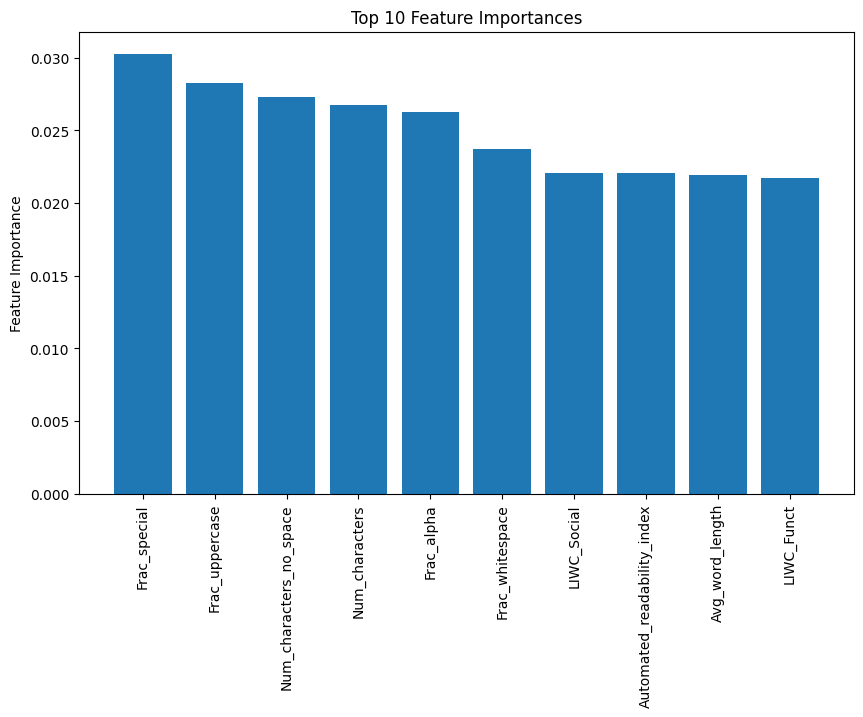

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Extract importances and feature names
importances = rf.feature_importances_
feature_names = X_train.columns

# Sort and select top 10
idx = np.argsort(importances)[-10:]
top_features = feature_names[idx]
top_importances = importances[idx]

# Plot
plt.figure(figsize=(10, 6))
plt.bar(top_features[::-1], top_importances[::-1])
plt.ylabel("Feature Importance")
plt.xticks(rotation=90)
plt.title("Top 10 Feature Importances")
plt.savefig("top_10_feature_importances.svg", format="svg", bbox_inches='tight')
